In [1]:
import numpy as np
import sklearn.linear_model
import sklearn.metrics
import sklearn.preprocessing
import matplotlib.pyplot as plt

from utils import get_random_poly2D_ds

## Datasets

In [2]:
ds = np.genfromtxt('../datasets/ds_altezzapeso.csv', delimiter=';')
x = ds[:,:1]
y = ds[:,1:]

print(f"X: \nSHAPE = {x.shape}")
print(f"{x[0:5,:]}\n")
print(f"Y: \nSHAPE = {y.shape}")
print(f"{y[0:5,:]}\n")

X: 
SHAPE = (1034, 1)
[[1.62110522]
 [1.76461064]
 [1.75572064]
 [1.66003453]
 [1.72650074]]

Y: 
SHAPE = (1034, 1)
[[54.87610387]
 [62.17308969]
 [55.15996198]
 [56.93205665]
 [46.37501175]]



## Regressione Polinomiale

### Metodo 1: Regressione Polinomiale di numpy

Parametri:
[ 19.52796065 -10.04201317  16.78439885]

Regressore Polinomiale:
y = +19.53x^2 -10.04x +16.78


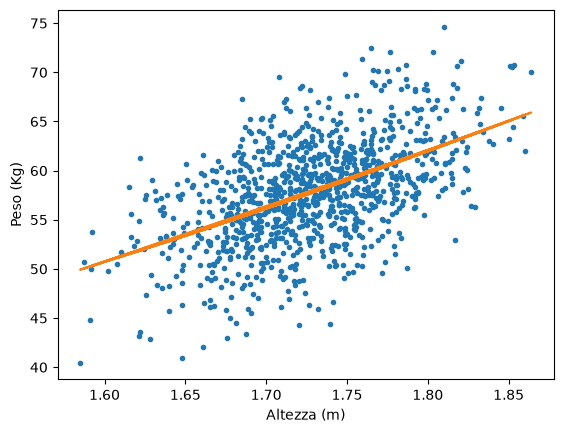

In [3]:
poly_reg = np.polyfit(ds[:,0], ds[:,1], deg=2)
params = poly_reg

print("Parametri:")
print(params)
print()

print("Regressore Polinomiale:")
print(f"y = {params[0]:+.2f}x^2 {params[1]:+.2f}x {params[2]:+.2f}")

yt = np.polyval(poly_reg, x)

plt.xlabel("Altezza (m)")
plt.ylabel("Peso (Kg)")
plt.plot(x,y,'.')
plt.plot(x,yt,'-')
plt.show()

### Metodo 2: Regressione Lineare Multipla

In [4]:
xx = np.block([x*x,x])
lin_reg_m = sklearn.linear_model.LinearRegression()
lin_reg_m.fit(xx, y)

print("Parametri:")
print(lin_reg_m.coef_[0], lin_reg_m.intercept_)
print()

print("Regressore Polinomiale")
a2, a1 = lin_reg_m.coef_[0]
print(f"y = {a2:.2f}x^2 {a1:+.2f}x {lin_reg_m.intercept_[0]:+.2f}")



Parametri:
[ 19.52796065 -10.04201317] [16.78439885]

Regressore Polinomiale
y = 19.53x^2 -10.04x +16.78


Funzione Polinomiale:
        5         4         3         2
7.178 x - 2.546 x + 1.103 x + 9.113 x + 4.733 x + 6.324


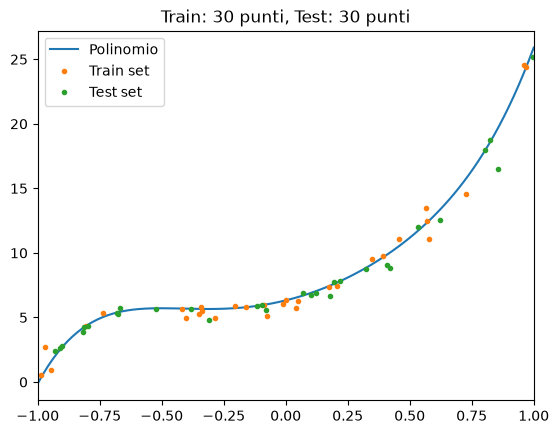

In [9]:
np.random.seed(32)

deg_ds = 5 # Grado del polinomio che vogliamo generare (in questo caso: polinomio di 5° grado)
n = 50    # Numero di campioni che vogliamo generare per il dataset
poly_reg = np.poly1d(np.random.random(deg_ds + 1) * 20 - 10) # Creiamo un polinomio casuale di grado 'deg_ds' con i coefficienti in [-10, 10]

# Stampiamo il polinomio generato in forma leggibile
print("Funzione Polinomiale:\n", poly_reg)


x_train, y_train, x_test, y_test = get_random_poly2D_ds(n, poly_reg, test_size=0.5, to_plot=True)

x_min = np.min(x_train)
x_max = np.max(x_train)

y_min = np.min(y_train)
y_max = np.max(y_train)

x_train = (x_train - x_min) / (x_max - x_min)
y_train = (y_train - y_min) / (y_max - y_min)

x_test = (x_test - x_min) / (x_max - x_min)
y_test = (y_test - y_min) / (y_max - y_min)

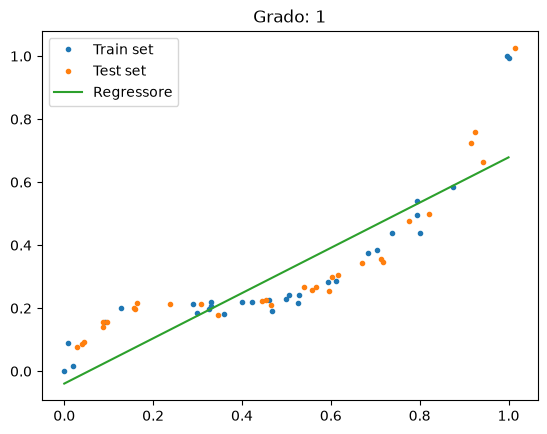

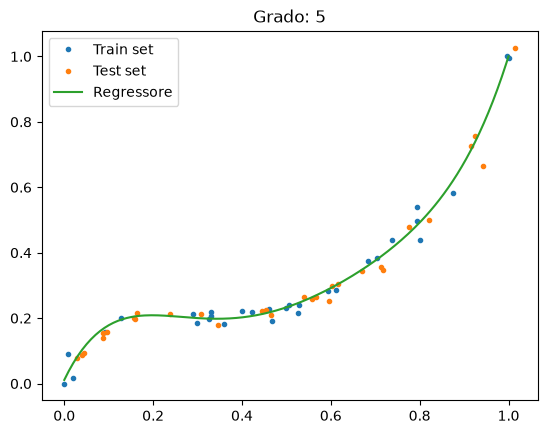

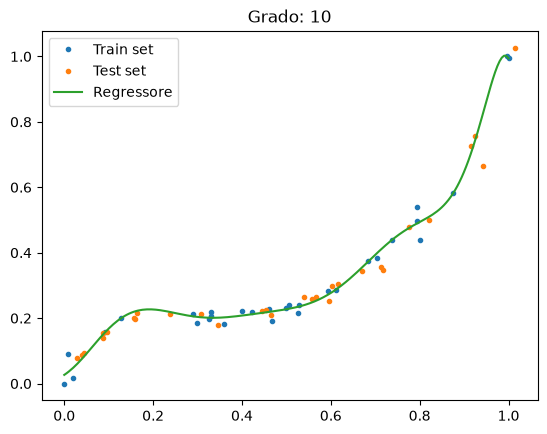

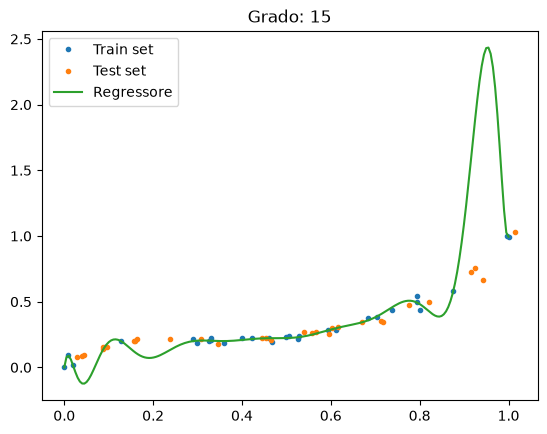

C:\Users\Francesco De Luca\AppData\Local\Temp\ipykernel_22368\648727618.py:7: RankWarning: Polyfit may be poorly conditioned
  curr_poly = np.polyfit(x_train,y_train,deg_train)


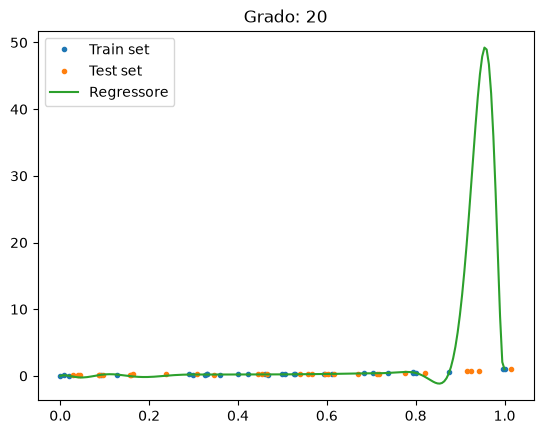

C:\Users\Francesco De Luca\AppData\Local\Temp\ipykernel_22368\648727618.py:7: RankWarning: Polyfit may be poorly conditioned
  curr_poly = np.polyfit(x_train,y_train,deg_train)


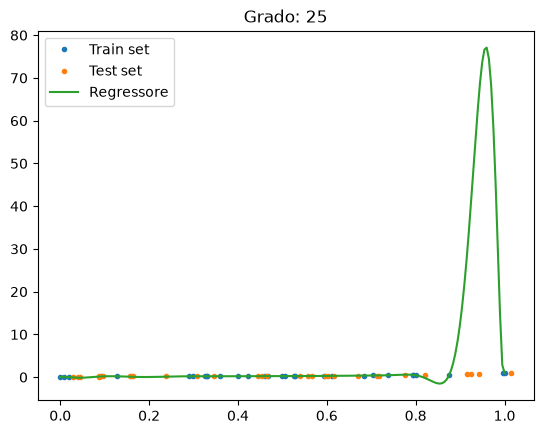

C:\Users\Francesco De Luca\AppData\Local\Temp\ipykernel_22368\648727618.py:7: RankWarning: Polyfit may be poorly conditioned
  curr_poly = np.polyfit(x_train,y_train,deg_train)


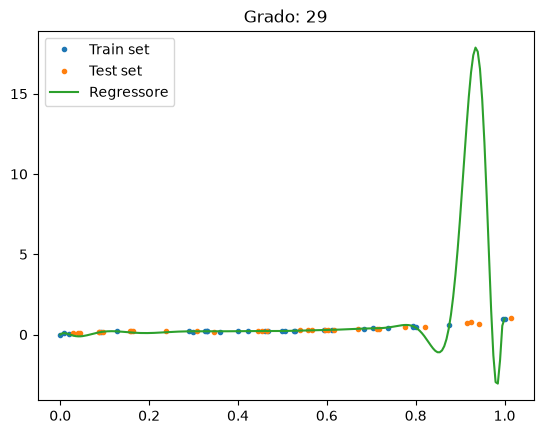

In [10]:
degrees = [1,5,10,15,20,25,29]
nd = len(degrees)
error = np.zeros((nd,2))

for i, deg_train in enumerate(degrees):
    curr_poly = np.polyfit(x_train,y_train,deg_train)
    p = np.poly1d(curr_poly)
    error_train = sklearn.metrics.mean_squared_error(y_train,p(x_train))
    error_test = sklearn.metrics.mean_squared_error(y_test,p(x_test))
    error[i,0] = error_train
    error[i,1] = error_test

    dsx = np.linspace(x_train.min(), x_train.max(), 200)
    plt.plot(x_train,y_train,'.', label = "Train set")
    plt.plot(x_test,y_test,'.', label = "Test set")
    plt.plot(dsx,p(dsx), label = "Regressore")
    plt.legend()
    plt.title(f"Grado: {deg_train}")
    plt.show()

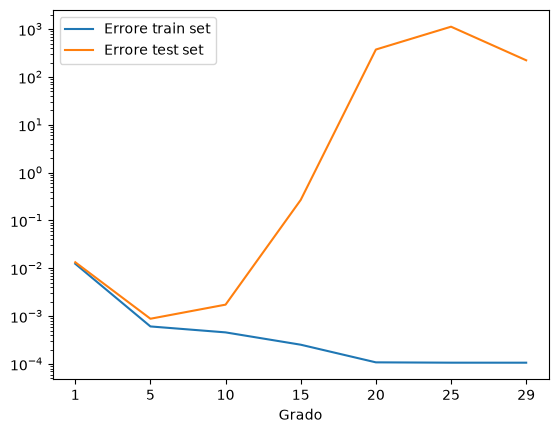

In [11]:
plt.figure()
plt.xlabel("Grado")
plt.semilogy([str(x) for x in degrees], error[:,0])
plt.semilogy([str(x) for x in degrees], error[:,1])
plt.legend(["Errore train set", "Errore test set"])
plt.show()